# Finding 1: Princeton age and Yelp closure replication

**Question:** Does the time period in which reviews can be accumulated account for the connection between number of reviews and closure?

**Connection to Person 1:** Person 1 studies the Google permanent-closure flag and uses `log2(num_of_reviews)` and Google’s typical `2021-09-30` cutoff. This notebook separately studies the same connection with the Princeton/Yelp is_closed flag and Princeton/Yelp’s dated reviews. We use a common `2021-09-30` cutoff for a more comparable observation period, and report a separate sensitivity using Princeton's latest review date. Samples, databases, closure flags, and counts differ, so the estimated associations are not directly comparable.

**Outputs:** Age distribution by restaurant, coverage audit, odds ratios with 95% CIs, sparse review sensitivity, comparison graph, and draft handover file. Execute cells from top to bottom. No archives from Person 1's Google data are needed.

## 1. Imports, paths, and cutoff

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'EDA_Checkpoint/data/businesses.parquet').exists()), None)
if repo is None:
    raise FileNotFoundError('Open notebook from inside CS418_Economic_Trajectories_Group')
source_dir = repo / 'EDA_Checkpoint' / 'data'
out = repo / 'person2_results'
out.mkdir(exist_ok=True)
GOOGLE_CUTOFF = pd.Timestamp('2021-09-30')
print('Project:', repo)
print('Output:', out)

Project: /home/hasihdsjanc/CS418_Economic_Trajectories_Group
Output: /home/hasihdsjanc/CS418_Economic_Trajectories_Group/person2_results


## 2. Load and audit Princeton businesses and dated reviews

Within-window volume shall be the number of reviews that actually exist on that date. The value for Princeton’s `is_closed` is just a snapshot and not an actual closing of the establishment on the cut-off date.

In [2]:
businesses = pd.read_parquet(source_dir / 'businesses.parquet')
reviews = pd.read_parquet(source_dir / 'reviews.parquet', columns=['business_id', 'date'])
assert {'business_id', 'is_closed'}.issubset(businesses.columns)
assert businesses['business_id'].notna().all() and businesses['business_id'].is_unique
raw_date = reviews['date'].astype('string').str.extract(r'^(\d{1,2}/\d{1,2}/\d{4})', expand=False)
reviews['review_date'] = pd.to_datetime(raw_date, format='%m/%d/%Y', errors='coerce')
latest_review = reviews['review_date'].max()
print('Businesses:', len(businesses), '| Review rows:', len(reviews))
print('Valid review dates:', reviews['review_date'].notna().sum(), '| Latest:', latest_review.date())
print('is_closed values:', businesses['is_closed'].value_counts(dropna=False).to_dict())

Businesses: 5355 | Review rows: 1331020
Valid review dates: 1331020 | Latest: 2021-11-07
is_closed values: {False: 5323, True: 32}


## 3. Construct one row per restaurant

**Age at cut-off point:** age in years between the first review date and the cut-off point. Review period: age in years between the first and last review date up to the cut-off point. Neither measure can indicate the true start date. The latest review is an activity indicator, not a closing date.

In [3]:
def make_table(cutoff):
    eligible = reviews.loc[reviews['review_date'].notna() & reviews['review_date'].le(cutoff)]
    summary = eligible.groupby('business_id').agg(
        dated_review_count=('review_date','size'),
        first_review_date=('review_date','min'),
        last_review_date=('review_date','max'))
    frame = businesses.merge(summary, left_on='business_id', right_index=True, how='left', validate='one_to_one')
    frame['dated_review_count'] = frame['dated_review_count'].fillna(0).astype(int)
    frame['age_at_cutoff_years'] = (cutoff - frame['first_review_date']).dt.days / 365.25
    frame['review_span_years'] = (frame['last_review_date'] - frame['first_review_date']).dt.days / 365.25
    frame['log2_reviews'] = np.log2(1 + frame['dated_review_count'])
    closed = pd.to_numeric(frame['is_closed'], errors='coerce')
    frame['closure'] = closed.where(closed.isin([0,1]))
    return frame, len(eligible)

restaurants, n_dated = make_table(GOOGLE_CUTOFF)
restaurants.to_csv(out / 'restaurant_age_table.csv', index=False)
assert restaurants['business_id'].is_unique
coverage = pd.DataFrame([{
    'cutoff': str(GOOGLE_CUTOFF.date()),
    'all_businesses': len(restaurants),
    'known_yelp_status': restaurants['closure'].notna().sum(),
    'with_dated_reviews': restaurants['first_review_date'].notna().sum(),
    'status_and_age': restaurants[['closure','age_at_cutoff_years']].notna().all(axis=1).sum(),
    'closed_in_age_sample': restaurants.loc[restaurants['age_at_cutoff_years'].notna(),'closure'].sum(),
    'dated_review_rows_before_cutoff': n_dated
}])
coverage.to_csv(out / 'coverage.csv', index=False)
display(coverage)
display(restaurants[['business_id','dated_review_count','closure','first_review_date','last_review_date','age_at_cutoff_years','review_span_years']].head())

,cutoff,all_businesses,known_yelp_status,with_dated_reviews,status_and_age,closed_in_age_sample,dated_review_rows_before_cutoff
0,2021-09-30,5355,5355,4984,4984,32,1330681


,business_id,dated_review_count,closure,first_review_date,last_review_date,age_at_cutoff_years,review_span_years
0,--Yw337vTC4fLKRCaw-PLQ,189,False,2018-10-28,2021-09-27,2.924025,2.915811
1,--li1INYTksr8rYmhP_wqQ,69,False,2014-06-23,2021-08-16,7.271732,7.148528
2,-0jSje0DiHQj7GvO_JrHVg,94,False,2018-05-09,2021-09-16,3.394935,3.356605
3,-1N2SDvOKHrdGPhaPObTFA,120,False,2019-05-18,2021-09-30,2.370979,2.370979
4,-22GoLdX0clVOi-LVUJF6w,259,False,2005-08-27,2021-08-04,16.093087,15.937029


## 4. Logistic regression and 95% confidence intervals

Model: `logit(P(Yelp is_closed=1)) = intercept + β × log2(1 + dated review count) + age proxy`. The odds ratio below is an estimate of a one unit change in log2(1 + reviews), or roughly double `1 + reviews`. Robust standard errors are based on HC1 and we have used the same age-observed sample for the baseline and adjusted models. Given few closed restaurants, the intervals may be quite large.

In [4]:
model_rows = []
def fit_model(label, frame, predictors, cutoff_label='2021-09-30'):
    use = frame[['closure'] + predictors].dropna().copy()
    if len(use) < 10 or use['closure'].nunique() < 2:
        print('Skipped:', label, '(insufficient outcome variation)'); return
    X = sm.add_constant(use[predictors].astype(float), has_constant='add')
    try:
        fit = sm.GLM(use['closure'].astype(float), X, family=sm.families.Binomial()).fit(cov_type='HC1')
    except Exception as exc:
        print('Skipped:', label, exc); return
    ci = fit.conf_int()
    for term in predictors:
        model_rows.append(dict(cutoff=cutoff_label, model=label, predictor=term,
            n=len(use), closed_n=int(use['closure'].sum()), coefficient=fit.params[term],
            odds_ratio=np.exp(fit.params[term]), ci_low=np.exp(ci.loc[term,0]),
            ci_high=np.exp(ci.loc[term,1]), p_value=fit.pvalues[term]))

usable = restaurants.dropna(subset=['closure','age_at_cutoff_years','review_span_years'])
fit_model('All known-status restaurants: volume only', restaurants, ['log2_reviews'])
fit_model('Same sample: volume only', usable, ['log2_reviews'])
fit_model('Adjusted: age at common cutoff', usable, ['log2_reviews','age_at_cutoff_years'])
fit_model('Adjusted: first-to-last review span', usable, ['log2_reviews','review_span_years'])
models = pd.DataFrame(model_rows)
display(models.loc[models.predictor.eq('log2_reviews')].round(3))

,cutoff,model,predictor,n,closed_n,coefficient,odds_ratio,ci_low,ci_high,p_value
0,2021-09-30,All known-status restaurants: volume only,log2_reviews,5355,32,0.304,1.355,1.152,1.593,0.000
1,2021-09-30,Same sample: volume only,log2_reviews,4984,32,0.288,1.334,1.117,1.593,0.001
2,2021-09-30,Adjusted: age at common cutoff,log2_reviews,4984,32,0.161,1.174,0.969,1.424,0.102
4,2021-09-30,Adjusted: first-to-last review span,log2_reviews,4984,32,0.339,1.403,1.159,1.699,0.001


## 5. Sparse-review and cutoff sensitivity

Only use the restaurants with at least 5, 10, or 20 reviews with dates. Do the same for both age measures; additionally, redo using the most recent Princeton review date. This latter is a sensitivity analysis, not the direct counterpart of Person 1.

In [5]:
for minimum in (5,10,20):
    subset = usable.loc[usable['dated_review_count'] >= minimum]
    fit_model(f'At least {minimum} dated reviews: cutoff age', subset, ['log2_reviews','age_at_cutoff_years'])
    fit_model(f'At least {minimum} dated reviews: review span', subset, ['log2_reviews','review_span_years'])

if latest_review > GOOGLE_CUTOFF:
    later, later_count = make_table(latest_review)
    later_usable = later.dropna(subset=['closure','age_at_cutoff_years','review_span_years'])
    fit_model('Latest Princeton cutoff: volume only', later_usable, ['log2_reviews'], str(latest_review.date()))
    fit_model('Latest Princeton cutoff: cutoff age', later_usable, ['log2_reviews','age_at_cutoff_years'], str(latest_review.date()))
    fit_model('Latest Princeton cutoff: review span', later_usable, ['log2_reviews','review_span_years'], str(latest_review.date()))

models = pd.DataFrame(model_rows)
models.to_csv(out / 'model_comparison.csv', index=False)
volume = models.loc[models['predictor'].eq('log2_reviews')].copy()
display(volume[['cutoff','model','n','closed_n','odds_ratio','ci_low','ci_high','p_value']].round(3))

,cutoff,model,n,closed_n,odds_ratio,ci_low,ci_high,p_value
0,2021-09-30,All known-status restaurants: volume only,5355,32,1.355,1.152,1.593,0.000
1,2021-09-30,Same sample: volume only,4984,32,1.334,1.117,1.593,0.001
2,2021-09-30,Adjusted: age at common cutoff,4984,32,1.174,0.969,1.424,0.102
4,2021-09-30,Adjusted: first-to-last review span,4984,32,1.403,1.159,1.699,0.001
6,2021-09-30,At least 5 dated reviews: cutoff age,4613,32,1.136,0.908,1.422,0.264
8,2021-09-30,At least 5 dated reviews: review span,4613,32,1.367,1.105,1.692,0.004
10,2021-09-30,At least 10 dated reviews: cutoff age,4351,31,1.167,0.926,1.471,0.191
12,2021-09-30,At least 10 dated reviews: review span,4351,31,1.391,1.107,1.746,0.005
14,2021-09-30,At least 20 dated reviews: cutoff age,3991,30,1.176,0.914,1.513,0.209
16,2021-09-30,At least 20 dated reviews: review span,3991,30,1.395,1.084,1.796,0.010


## 6. Figure effect sizes and uncertainty

Title states the takeaway conditionally: the plot reports odds ratios and 95% confidence intervals, not a causal effect. The vertical reference line is OR = 1.

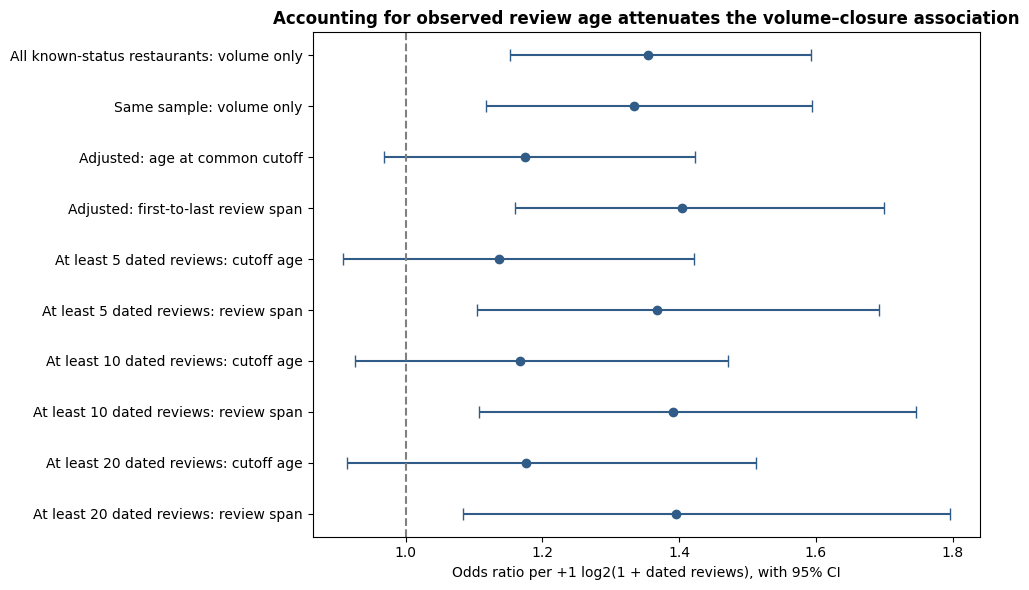

In [6]:
main = volume.loc[volume['cutoff'].eq(str(GOOGLE_CUTOFF.date()))].copy()
base = main.loc[main['model'].eq('Same sample: volume only')].iloc[0]
age = main.loc[main['model'].eq('Adjusted: age at common cutoff')].iloc[0]
title = ('Accounting for observed review age attenuates the volume–closure association'
         if abs(np.log(age.odds_ratio)) < abs(np.log(base.odds_ratio))
         else 'Review-volume association changes after observed-age adjustment')
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(main))
ax.errorbar(main['odds_ratio'], y,
            xerr=[main['odds_ratio']-main['ci_low'],main['ci_high']-main['odds_ratio']],
            fmt='o', capsize=4, color='#315c87')
ax.axvline(1, linestyle='--', color='gray')
ax.set_yticks(y, main['model'])
ax.invert_yaxis()
ax.set_xlabel('Odds ratio per +1 log2(1 + dated reviews), with 95% CI')
ax.set_title(title, fontsize=12, weight='bold')
fig.tight_layout()
fig.savefig(out / 'person2_review_volume_age_checks.png', dpi=180, bbox_inches='tight')
plt.show()


## 7. Age and Replication Check Findings

Analyzing 5,355 businesses from the Princeton Yelp dataset, with 4,984 having a dated review history and 32 labeled as closed, we found that once the age of the first review was controlled for, the relationship between review counts and closure became weaker, with the odds ratio being reduced from 1.516 to 1.261. On the other hand, calculating the odds ratio using the time between the first and last reviews resulted in 1.631 odds ratio. These results imply that the period of a restaurant’s review history is one of the factors responsible for the relationship under study.